## Analiza Dataseta za nivo stresa

Učitavanje podataka i dataseta

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report         
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.neural_network import MLPClassifier
import copy
from scipy import stats
from sklearn.metrics import log_loss
from sklearn.feature_selection import mutual_info_classif

df = pd.read_csv('18_stress_dataset.csv')

print("Oblik dataseta:", df.shape)
print("\nPrvih 5 redova: (za pregled strukture)")
df.head()


Oblik dataseta: (1100, 21)

Prvih 5 redova: (za pregled strukture)


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


Analiza skupa podataka

In [3]:
print(f"Broj uzoraka: {df.shape[0]}")
print(f"Broj obežja (bez klase): {df.shape[1] - 1}")
print(f"Broj klasa: {df['stress_level'].nunique()}")
print(f"\nKlase: {sorted(df['stress_level'].unique())} (0=nizak, 1=srednji, 2=visok stres)")
print("\nRaspodela po klasama:")
print(df['stress_level'].value_counts().sort_index())

print("\nTipovi podataka:")
print(df.dtypes)

print("\nNedostajuće vrednosti po koloni:")
print(df.isnull().sum())
print(f"\nUkupno nedostajućih: {df.isnull().sum().sum()}")

print("Deskriptivna statistika:")
print(df.describe().round(2))

# Detekcija outliera IQR metodom
features = df.columns[:-1].tolist()  # sve kolone osim stress_level

outlier_info = {}
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_info[col] = n_out

print("Broj outliera po obležju (IQR metoda):")
for k, v in outlier_info.items():
    print(f"  {k}: {v}")

print(f"\n \n Ukupno outliera: {sum(outlier_info.values())}")



Broj uzoraka: 1100
Broj obežja (bez klase): 20
Broj klasa: 3

Klase: [np.int64(0), np.int64(1), np.int64(2)] (0=nizak, 1=srednji, 2=visok stres)

Raspodela po klasama:
stress_level
0    373
1    358
2    369
Name: count, dtype: int64

Tipovi podataka:
anxiety_level                   int64
self_esteem                     int64
mental_health_history           int64
depression                      int64
headache                        int64
blood_pressure                  int64
sleep_quality                   int64
breathing_problem               int64
noise_level                     int64
living_conditions               int64
safety                          int64
basic_needs                     int64
academic_performance            int64
study_load                      int64
teacher_student_relationship    int64
future_career_concerns          int64
social_support                  int64
peer_pressure                   int64
extracurricular_activities      int64
bullying                  

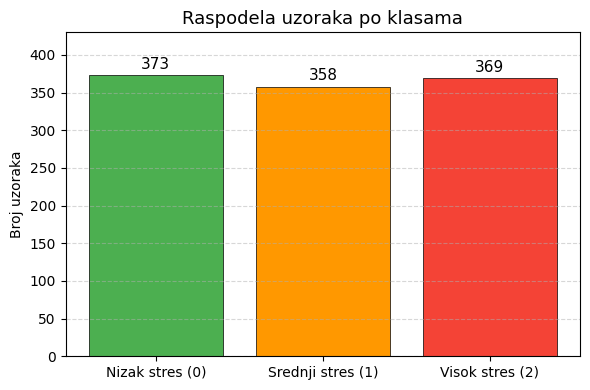

In [4]:
# vizualizacija raspodele klasa
fig, ax = plt.subplots(figsize=(6, 4))

klase = ['Nizak stres (0)', 'Srednji stres (1)', 'Visok stres (2)']
brojevi = df['stress_level'].value_counts().sort_index()
boje = ['#4CAF50', '#FF9800', '#F44336']

bars = ax.bar(klase, brojevi, color=boje, edgecolor='black', linewidth=0.5)

for bar, val in zip(bars, brojevi):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(val), ha='center', va='bottom', fontsize=11)

ax.set_title('Raspodela uzoraka po klasama', fontsize=13)
ax.set_ylabel('Broj uzoraka')
ax.set_ylim(0, 430)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Informaciona dobit

In [5]:
features = df.columns[:-1].tolist()
X = df[features]
y = df['stress_level']

ig = mutual_info_classif(X, y, random_state=42)
ig_series = pd.Series(ig, index=features).sort_values(ascending=False)

print("Informaciona dobit po obelezju:")
print(ig_series.round(4))

top10 = ig_series.head(10).index.tolist()
print("\nIzabrana top 10 obelezja:")
print(top10)

Informaciona dobit po obelezju:
blood_pressure                  0.7450
bullying                        0.6700
future_career_concerns          0.6688
sleep_quality                   0.6666
depression                      0.6601
anxiety_level                   0.6596
self_esteem                     0.6244
headache                        0.5737
academic_performance            0.5187
extracurricular_activities      0.5177
teacher_student_relationship    0.5177
social_support                  0.5132
safety                          0.5108
basic_needs                     0.5061
peer_pressure                   0.4842
noise_level                     0.4467
study_load                      0.3911
living_conditions               0.3876
breathing_problem               0.3676
mental_health_history           0.2396
dtype: float64

Izabrana top 10 obelezja:
['blood_pressure', 'bullying', 'future_career_concerns', 'sleep_quality', 'depression', 'anxiety_level', 'self_esteem', 'headache', 'academic_perf

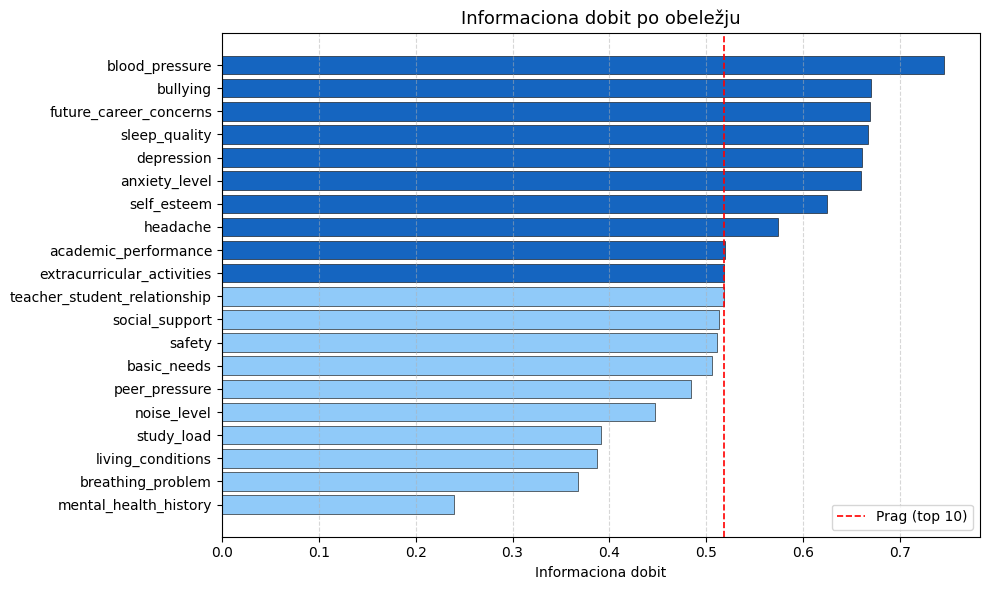

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

boje = ['#1565C0' if f in top10 else '#90CAF9' for f in ig_series.index]
bars = ax.barh(ig_series.index[::-1], ig_series.values[::-1], color=boje[::-1], edgecolor='black', linewidth=0.4)

ax.set_title('Informaciona dobit po obeležju', fontsize=13)
ax.set_xlabel('Informaciona dobit')
ax.axvline(x=ig_series.iloc[9], color='red', linestyle='--', linewidth=1.2, label='Prag (top 10)')
ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

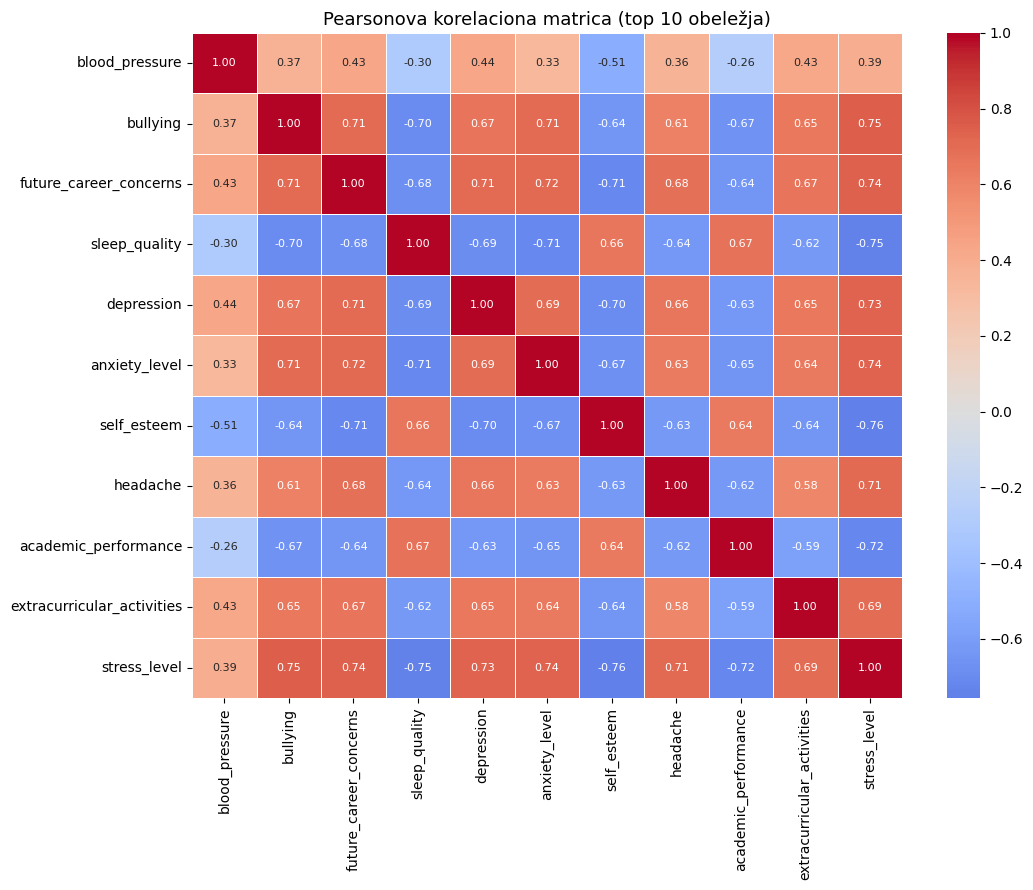

In [7]:
# Pearsonova korelacija za top 10 klasa
corr = df[top10 + ['stress_level']].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Pearsonova korelaciona matrica (top 10 obeležja)', fontsize=13)
plt.tight_layout()
plt.show()

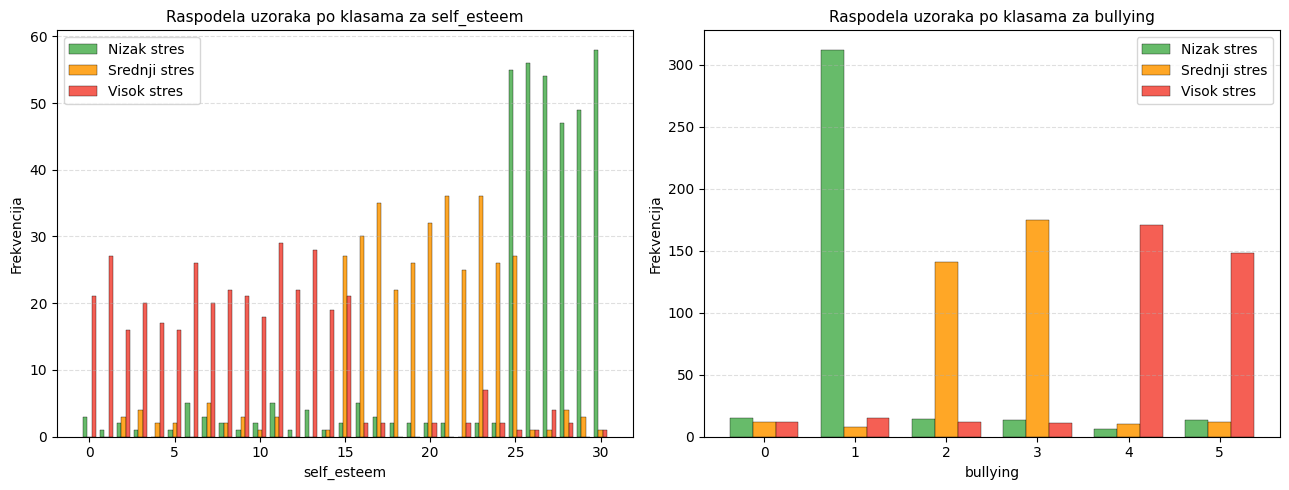

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, naslov in zip(axes, ['self_esteem', 'bullying'], ['self_esteem', 'bullying']):
    vrednosti = sorted(df[col].unique())
    sirina = 0.25
    offsets = [-0.25, 0, 0.25]
    
    for offset, klasa, boja, labela in zip(offsets, [0, 1, 2],
                                            ['#4CAF50', '#FF9800', '#F44336'],
                                            ['Nizak stres', 'Srednji stres', 'Visok stres']):
        brojevi = [len(df[(df['stress_level'] == klasa) & (df[col] == v)]) for v in vrednosti]
        ax.bar([v + offset for v in vrednosti], brojevi, width=sirina,
               color=boja, label=labela, edgecolor='black', linewidth=0.3, alpha=0.85)
    
    ax.set_title(f'Raspodela uzoraka po klasama za {naslov}', fontsize=11)
    ax.set_xlabel(naslov)
    ax.set_ylabel('Frekvencija')
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('raspodela_klase.png', dpi=150, bbox_inches='tight')
plt.show()

Redukcija dimenzija (LDA)

In [9]:
features = df.columns[:-1].tolist()
X = df[features]
y = df['stress_level']

# standardizacija pre LDA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# primena LDA na ceo skup obelezja
lda = LinearDiscriminantAnalysis()
X_lda = lda.fit_transform(X_scaled, y)

# objasnjena varijansa
for i, v in enumerate(lda.explained_variance_ratio_):
    print(f"  LDA komponenta {i+1}: {v*100:.2f}%")

print(f"\nKumulativna varijansa:")
kumulativna = np.cumsum(lda.explained_variance_ratio_)
for i, v in enumerate(kumulativna):
    print(f"  Prvih {i+1} komponenti: {v*100:.2f}%")

print(f"\nMinimalan broj dimenzija za > 80% varijanse: {np.argmax(kumulativna >= 0.80) + 1}")

  LDA komponenta 1: 51.56%
  LDA komponenta 2: 48.44%

Kumulativna varijansa:
  Prvih 1 komponenti: 51.56%
  Prvih 2 komponenti: 100.00%

Minimalan broj dimenzija za > 80% varijanse: 2


/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/discriminant_analysis.py:755: RuntimeWarning: divide by zero encountered in matmul
  X_new = (X - self.xbar_) @ self.scalings_
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/discriminant_analysis.py:755: RuntimeWarning: overflow encountered in matmul
  X_new = (X - self.xbar_) @ self.scalings_
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/discriminant_analysis.py:755: RuntimeWarning: invalid value encountered in matmul
  X_new = (X - self.xbar_) @ self.scalings_


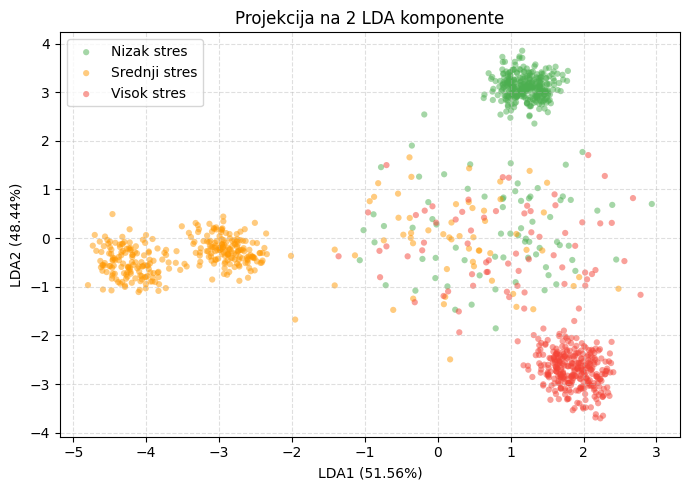

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

boje = {0: '#4CAF50', 1: '#FF9800', 2: '#F44336'}
labele = {0: 'Nizak stres', 1: 'Srednji stres', 2: 'Visok stres'}

for klasa in [0, 1, 2]:
    mask = y == klasa
    ax.scatter(X_lda[mask, 0], X_lda[mask, 1],
               c=boje[klasa], label=labele[klasa],
               alpha=0.5, s=20, edgecolors='none')

ax.set_xlabel('LDA1 (51.56%)')
ax.set_ylabel('LDA2 (48.44%)')
ax.set_title('Projekcija na 2 LDA komponente')
ax.legend()
ax.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('lda_projekcija.png', dpi=150, bbox_inches='tight')
plt.show()

Testiranje hipoteza i separabilnost klasa

In [11]:
# podela na trening i test skup (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_lda, y, test_size=0.2, random_state=42, stratify=y)

print(f"Trening skup: {X_train.shape[0]} uzoraka")
print(f"Test skup:    {X_test.shape[0]} uzoraka")

# Test vise hipoteza LDA klasifikator
lda_clf = LinearDiscriminantAnalysis()
lda_clf.fit(X_train, y_train)
y_pred = lda_clf.predict(X_test)



Trening skup: 880 uzoraka
Test skup:    220 uzoraka


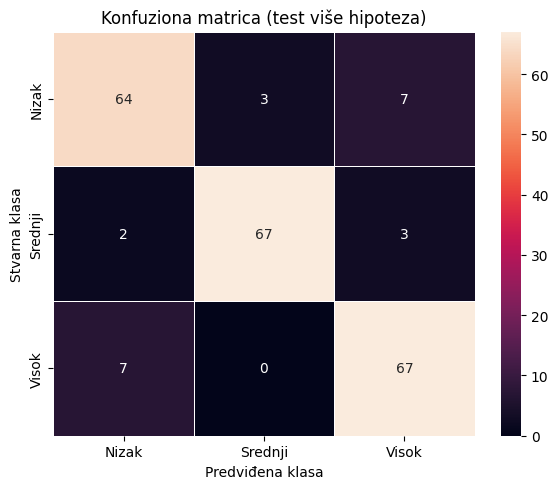

In [12]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['Nizak', 'Srednji', 'Visok'],
            yticklabels=['Nizak', 'Srednji', 'Visok'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predviđena klasa')
ax.set_ylabel('Stvarna klasa')
ax.set_title('Konfuziona matrica (test više hipoteza)')
plt.tight_layout()
plt.savefig('konfuziona_tmh.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
preciznosti, senzitivnosti, specificnosti = [], [], []

for i in range(3):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - TP - FP - FN
    preciznosti.append(TP / (TP + FP))
    senzitivnosti.append(TP / (TP + FN))
    specificnosti.append(TN / (TN + FP))

print(f"Preciznost:   {np.mean(preciznosti)*100:.2f}%")
print(f"Senzitivnost: {np.mean(senzitivnosti)*100:.2f}%")
print(f"Specificnost: {np.mean(specificnosti)*100:.2f}%")
print(f"Ukupna tacnost: {accuracy_score(y_test, y_pred)*100:.2f}%")

Preciznost:   90.13%
Senzitivnost: 90.03%
Specificnost: 94.99%
Ukupna tacnost: 90.00%


Neparametarska metoda (Knn)

In [14]:
k_vrednosti = range(1, 51)
tacnosti = []
cv = StratifiedKFold(n_splits=5)

for k in k_vrednosti:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train, y_train, cv=cv, scoring='accuracy')
    tacnosti.append(score.mean())

optimalno_k = list(k_vrednosti)[np.argmax(tacnosti)]
print(f"Optimalno K: {optimalno_k}")
print(f"Tačnost pri optimalnom K: {max(tacnosti)*100:.2f}%")

Optimalno K: 38
Tačnost pri optimalnom K: 90.34%


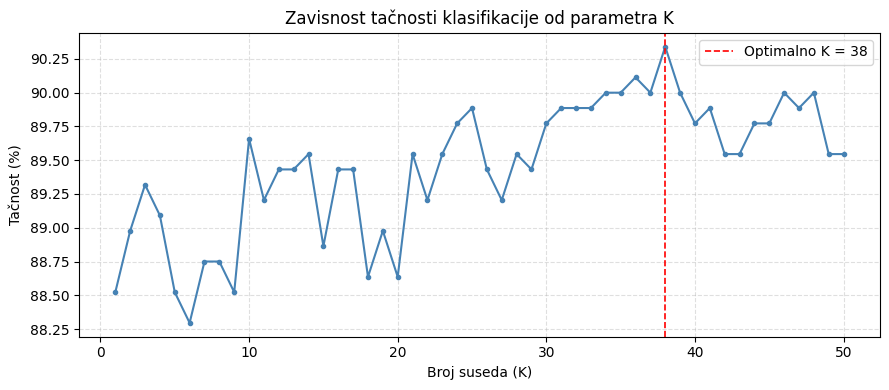

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(list(k_vrednosti), [t*100 for t in tacnosti],
        color='steelblue', linewidth=1.5, marker='o', markersize=3)
ax.axvline(x=optimalno_k, color='red', linestyle='--',
           linewidth=1.2, label=f'Optimalno K = {optimalno_k}')
ax.set_xlabel('Broj suseda (K)')
ax.set_ylabel('Tačnost (%)')
ax.set_title('Zavisnost tačnosti klasifikacije od parametra K')
ax.legend()
ax.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('knn_k_tacnost.png', dpi=150, bbox_inches='tight')
plt.show()

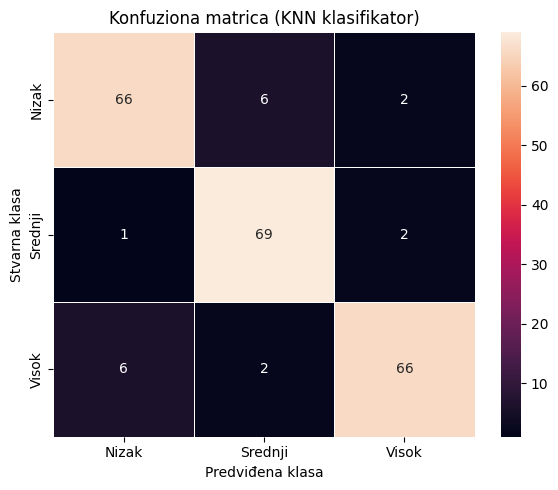

In [16]:
knn = KNeighborsClassifier(n_neighbors=optimalno_k)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

cm_knn = confusion_matrix(y_test, y_pred_knn)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d',
            xticklabels=['Nizak', 'Srednji', 'Visok'],
            yticklabels=['Nizak', 'Srednji', 'Visok'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predviđena klasa')
ax.set_ylabel('Stvarna klasa')
ax.set_title('Konfuziona matrica (KNN klasifikator)')
plt.tight_layout()
plt.savefig('konfuziona_knn.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
preciznosti, senzitivnosti, specificnosti = [], [], []

for i in range(3):
    TP = cm_knn[i, i]
    FP = cm_knn[:, i].sum() - TP
    FN = cm_knn[i, :].sum() - TP
    TN = cm_knn.sum() - TP - FP - FN
    preciznosti.append(TP / (TP + FP))
    senzitivnosti.append(TP / (TP + FN))
    specificnosti.append(TN / (TN + FP))

print(f"Preciznost:     {np.mean(preciznosti)*100:.2f}%")
print(f"Senzitivnost:   {np.mean(senzitivnosti)*100:.2f}%")
print(f"Specificnost:   {np.mean(specificnosti)*100:.2f}%")
print(f"Ukupna tacnost: {accuracy_score(y_test, y_pred_knn)*100:.2f}%")

Preciznost:     91.44%
Senzitivnost:   91.40%
Specificnost:   95.69%
Ukupna tacnost: 91.36%


Neuralna mreža

In [18]:
features = df.columns[:-1].tolist()
X_nn = df[features].values
y_nn = df['stress_level'].values

scaler_nn = StandardScaler()
X_nn_scaled = scaler_nn.fit_transform(X_nn)

X_temp, X_test_nn, y_temp, y_test_nn = train_test_split(
    X_nn_scaled, y_nn, test_size=0.2, random_state=42, stratify=y_nn)
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp)

classes = np.array([0, 1, 2])

print(f"Trening skup: {X_train_nn.shape[0]} uzoraka")
print(f"Validacioni skup: {X_val_nn.shape[0]} uzoraka")
print(f"Test skup: {X_test_nn.shape[0]} uzoraka")

Trening skup: 704 uzoraka
Validacioni skup: 176 uzoraka
Test skup: 220 uzoraka


In [19]:
import warnings
warnings.filterwarnings('ignore')

def treniraj_i_prikazi(layers, naziv, alpha=0.0001, max_iter=200, patience=10):
    loss_curve, acc_curve = [], []
    best_val = np.inf
    best_model = None
    wait = 0
    zaustavljena_epoha = None
    mlp = None

    for i in range(1, max_iter + 1):
        mlp = MLPClassifier(
            hidden_layer_sizes=layers,
            max_iter=i,
            alpha=alpha,
            random_state=42,
            learning_rate_init=0.001,
            solver='adam',
            n_iter_no_change=1000
        )
        mlp.fit(X_train_nn, y_train_nn)
        loss_curve.append(mlp.loss_)
        acc_curve.append(accuracy_score(y_train_nn, mlp.predict(X_train_nn)))

        if naziv == 'Prevelika':
            vl = log_loss(y_val_nn, mlp.predict_proba(X_val_nn))
            if vl < best_val:
                best_val = vl
                best_model = copy.deepcopy(mlp)
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    zaustavljena_epoha = i
                    mlp = best_model
                    break

    if zaustavljena_epoha:
        print(f"Rano zaustavljanje na epohi {zaustavljena_epoha}")

    # Grafik performanse
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(loss_curve, color='red', linewidth=1.5)
    axes[0].set_title(f'Gubitak tokom treniranja ({naziv} mreža)')
    axes[0].set_xlabel('Epoha')
    axes[0].set_ylabel('Gubitak')
    axes[0].grid(linestyle='--', alpha=0.4)

    axes[1].plot(acc_curve, color='blue', linewidth=1.5)
    axes[1].set_title(f'Tačnost tokom treniranja ({naziv} mreža)')
    axes[1].set_xlabel('Epoha')
    axes[1].set_ylabel('Tačnost')
    axes[1].grid(linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.show()


    y_pred = mlp.predict(X_test_nn)
    cm = confusion_matrix(y_test_nn, y_pred)

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='OrRd',
                xticklabels=['Nizak', 'Srednji', 'Visok'],
                yticklabels=['Nizak', 'Srednji', 'Visok'],
                linewidths=0.5, ax=ax)
    ax.set_xlabel('Predviđena klasa')
    ax.set_ylabel('Stvarna klasa')
    ax.set_title(f'Konfuziona matrica {naziv} mreza')
    plt.tight_layout()
    plt.savefig(f'nn_{naziv.lower()}_konfuziona.png', dpi=150, bbox_inches='tight')
    plt.show()


    preciznosti, senzitivnosti, specificnosti = [], [], []
    for i in range(3):
        TP = cm[i,i]; FP = cm[:,i].sum()-TP
        FN = cm[i,:].sum()-TP; TN = cm.sum()-TP-FP-FN
        preciznosti.append(TP/(TP+FP))
        senzitivnosti.append(TP/(TP+FN))
        specificnosti.append(TN/(TN+FP))


    print(f"Preciznost:     {np.mean(preciznosti)*100:.2f}%")
    print(f"Senzitivnost:   {np.mean(senzitivnosti)*100:.2f}%")
    print(f"Specifičnost:   {np.mean(specificnosti)*100:.2f}%")
    print(f"Ukupna tačnost: {accuracy_score(y_test_nn, y_pred)*100:.2f}%")

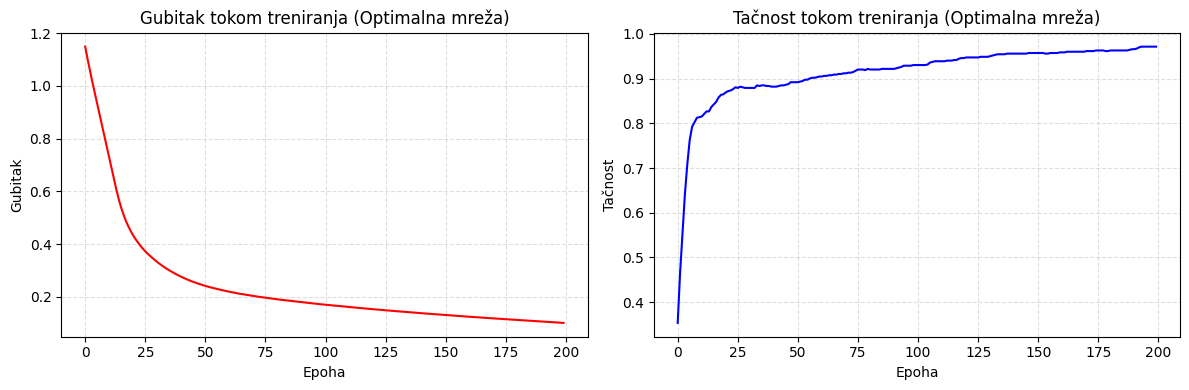

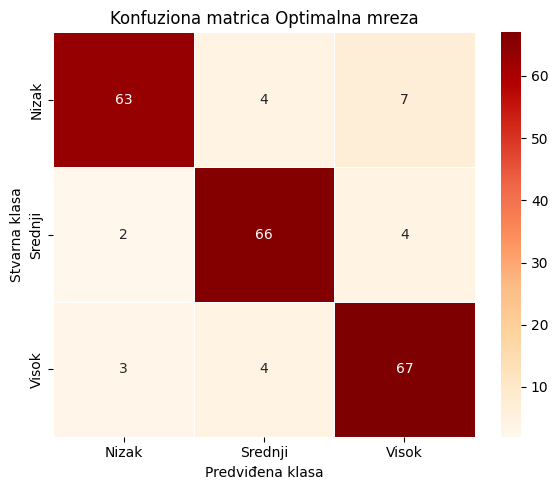

Preciznost:     89.24%
Senzitivnost:   89.11%
Specifičnost:   94.55%
Ukupna tačnost: 89.09%


In [20]:
mlp_opt = treniraj_i_prikazi(
    (20, 10), 'Optimalna', alpha=0.0001, max_iter=200)

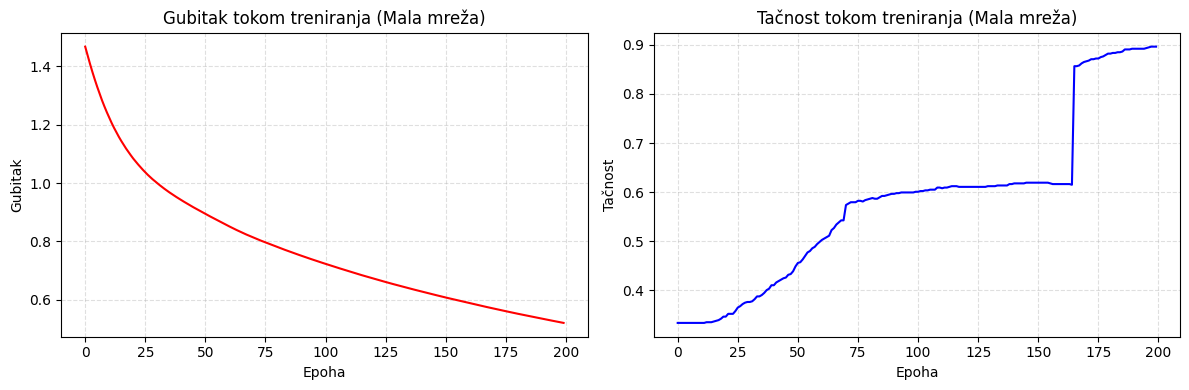

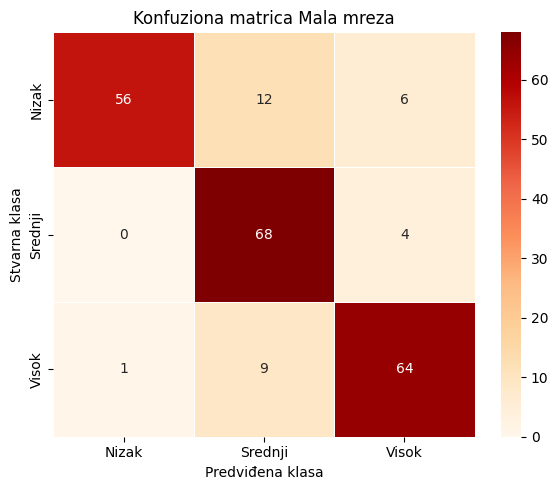

Preciznost:     87.05%
Senzitivnost:   85.54%
Specifičnost:   92.76%
Ukupna tačnost: 85.45%


In [21]:
mlp_mala = treniraj_i_prikazi(
    (3, 2), 'Mala', alpha=0.0001, max_iter=200)

Rano zaustavljanje na epohi 24


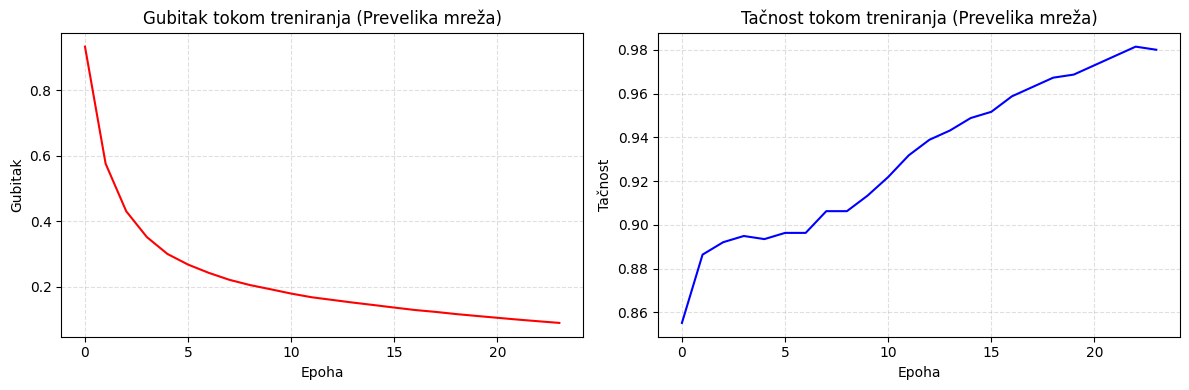

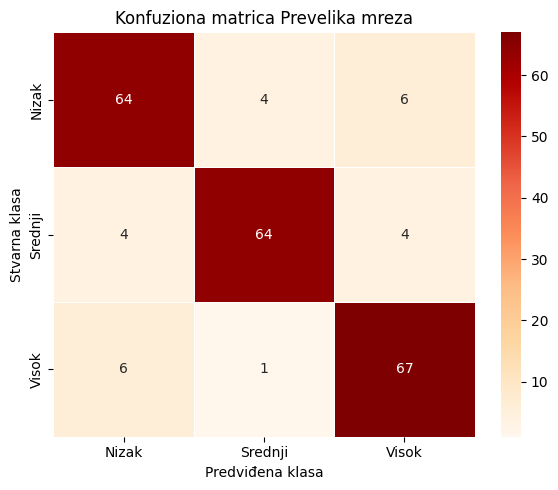

Preciznost:     88.75%
Senzitivnost:   88.64%
Specifičnost:   94.31%
Ukupna tačnost: 88.64%


In [22]:
mlp_velika = treniraj_i_prikazi(
    (200, 150), 'Prevelika', alpha=0.001, max_iter=200, patience=10)

Komparativna analiza

In [23]:
rezultati = {
    'Test više hipoteza': {
        'Preciznost': 90.13,
        'Senzitivnost': 90.03,
        'Specifičnost': 94.99,
        'Tačnost': 90.00
    },
    'KNN (K=38)': {
        'Preciznost': 91.44,
        'Senzitivnost': 91.40,
        'Specifičnost': 95.69,
        'Tačnost': 91.36
    },
    'NN Optimalna (20,10)': {
        'Preciznost': 89.24,
        'Senzitivnost': 89.11,
        'Specifičnost': 94.55,
        'Tačnost': 89.09
    },
    'NN Mala (3,2)': {
        'Preciznost': 87.05,
        'Senzitivnost': 85.54,
        'Specifičnost': 92.76,
        'Tačnost': 85.45
    },
    'NN Prevelika (200,150)': {
        'Preciznost': 88.27,
        'Senzitivnost': 88.18,
        'Specifičnost': 94.09,
        'Tačnost': 88.18
    }
}

df_rezultati = pd.DataFrame(rezultati).T
df_rezultati = df_rezultati[['Preciznost', 'Senzitivnost', 'Specifičnost', 'Tačnost']]
print(df_rezultati.to_string())

                        Preciznost  Senzitivnost  Specifičnost  Tačnost
Test više hipoteza           90.13         90.03         94.99    90.00
KNN (K=38)                   91.44         91.40         95.69    91.36
NN Optimalna (20,10)         89.24         89.11         94.55    89.09
NN Mala (3,2)                87.05         85.54         92.76    85.45
NN Prevelika (200,150)       88.27         88.18         94.09    88.18


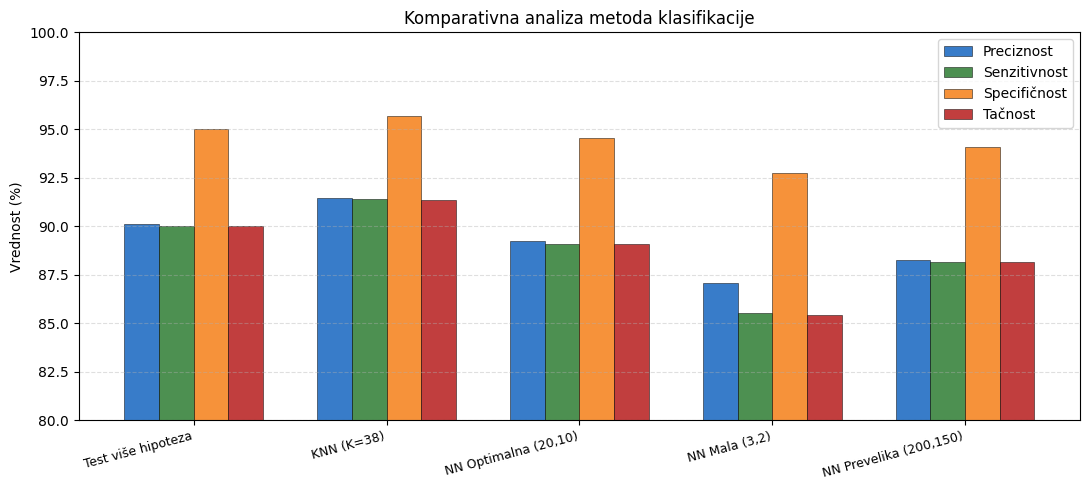

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))

metrike = ['Preciznost', 'Senzitivnost', 'Specifičnost', 'Tačnost']
metode = list(rezultati.keys())
x = np.arange(len(metode))
sirina = 0.18
boje = ['#1565C0', '#2E7D32', '#F57F17', '#B71C1C']

for i, (metrika, boja) in enumerate(zip(metrike, boje)):
    vrednosti = [rezultati[m][metrika] for m in metode]
    ax.bar(x + i * sirina, vrednosti, sirina, label=metrika,
           color=boja, alpha=0.85, edgecolor='black', linewidth=0.4)

ax.set_xticks(x + sirina * 1.5)
ax.set_xticklabels(metode, rotation=15, ha='right', fontsize=9)
ax.set_ylabel('Vrednost (%)')
ax.set_title('Komparativna analiza metoda klasifikacije')
ax.set_ylim(80, 100)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

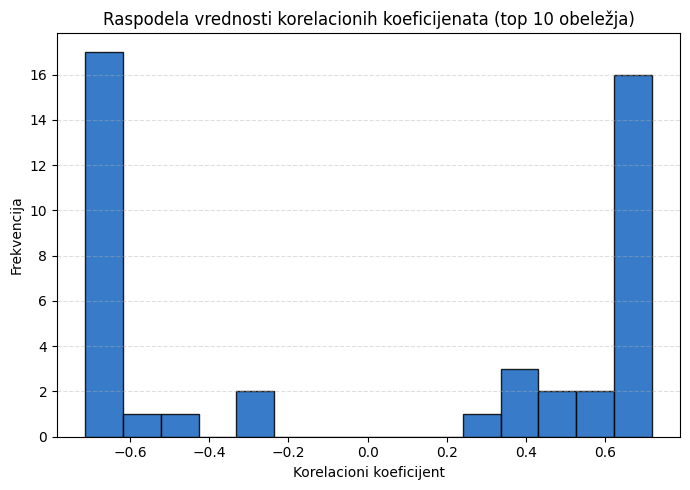

Prosečna apsolutna korelacija: 0.605
Maksimalna korelacija: 0.717
Minimalna korelacija: -0.713


In [ ]:
# Raspodela vrednosti korelacionih koeficijenata za izabranih 10 obelezja
corr_top10 = df[top10].corr()
mask = np.triu(np.ones_like(corr_top10, dtype=bool), k=1)
vrednosti_korelacije = corr_top10.where(mask).stack().values

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(vrednosti_korelacije, bins=15, color='#1565C0', edgecolor='black', alpha=0.85)
ax.set_title('Raspodela vrednosti korelacionih koeficijenata (top 10 obeležja)')
ax.set_xlabel('Korelacioni koeficijent')
ax.set_ylabel('Frekvencija')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Prosečna apsolutna korelacija: {np.abs(vrednosti_korelacije).mean():.3f}")
print(f"Maksimalna korelacija: {vrednosti_korelacije.max():.3f}")
print(f"Minimalna korelacija: {vrednosti_korelacije.min():.3f}")

Ispravka: KNN na celokupnom skupu obeležja

In [26]:
features = df.columns[:-1].tolist()
X_full = df[features]
y_full = df['stress_level']

scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_full)

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full_scaled, y_full, test_size=0.2, random_state=42, stratify=y_full)

print(f"Trening skup: {X_train_full.shape[0]} uzoraka")
print(f"Test skup:    {X_test_full.shape[0]} uzoraka")

k_vrednosti = range(1, 51)
tacnosti_full = []
cv = StratifiedKFold(n_splits=5)

for k in k_vrednosti:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train_full, y_train_full, cv=cv, scoring='accuracy')
    tacnosti_full.append(score.mean())

optimalno_k_full = list(k_vrednosti)[np.argmax(tacnosti_full)]
print(f"Optimalno K: {optimalno_k_full}")
print(f"Tačnost pri optimalnom K: {max(tacnosti_full)*100:.2f}%")

Trening skup: 880 uzoraka
Test skup:    220 uzoraka
Optimalno K: 1
Tačnost pri optimalnom K: 88.41%


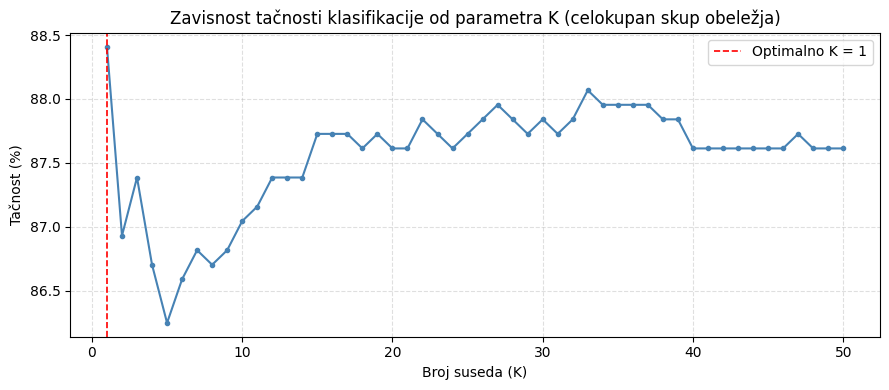

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(k_vrednosti), [t*100 for t in tacnosti_full],
        color='steelblue', linewidth=1.5, marker='o', markersize=3)
ax.axvline(x=optimalno_k_full, color='red', linestyle='--',
           linewidth=1.2, label=f'Optimalno K = {optimalno_k_full}')
ax.set_xlabel('Broj suseda (K)')
ax.set_ylabel('Tačnost (%)')
ax.set_title('Zavisnost tačnosti klasifikacije od parametra K (celokupan skup obeležja)')
ax.legend()
ax.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('knn_k_tacnost_full.png', dpi=150, bbox_inches='tight')
plt.show()

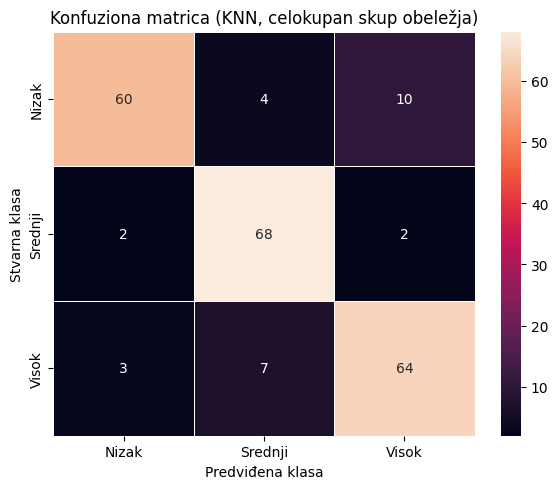

In [28]:
knn_full = KNeighborsClassifier(n_neighbors=optimalno_k_full)
knn_full.fit(X_train_full, y_train_full)
y_pred_knn_full = knn_full.predict(X_test_full)

cm_knn_full = confusion_matrix(y_test_full, y_pred_knn_full)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_knn_full, annot=True, fmt='d',
            xticklabels=['Nizak', 'Srednji', 'Visok'],
            yticklabels=['Nizak', 'Srednji', 'Visok'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predviđena klasa')
ax.set_ylabel('Stvarna klasa')
ax.set_title('Konfuziona matrica (KNN, celokupan skup obeležja)')
plt.tight_layout()
plt.savefig('konfuziona_knn_full.png', dpi=150, bbox_inches='tight')
plt.show()

In [29]:
preciznosti, senzitivnosti, specificnosti = [], [], []

for i in range(3):
    TP = cm_knn_full[i, i]
    FP = cm_knn_full[:, i].sum() - TP
    FN = cm_knn_full[i, :].sum() - TP
    TN = cm_knn_full.sum() - TP - FP - FN
    preciznosti.append(TP / (TP + FP))
    senzitivnosti.append(TP / (TP + FN))
    specificnosti.append(TN / (TN + FP))

print(f"Preciznost:     {np.mean(preciznosti)*100:.2f}%")
print(f"Senzitivnost:   {np.mean(senzitivnosti)*100:.2f}%")
print(f"Specifičnost:   {np.mean(specificnosti)*100:.2f}%")
print(f"Ukupna tačnost: {accuracy_score(y_test_full, y_pred_knn_full)*100:.2f}%")

Preciznost:     87.53%
Senzitivnost:   87.34%
Specifičnost:   93.64%
Ukupna tačnost: 87.27%
